# The Signal That Won't Stay Still: SBP Drift in Chronic BCI Recordings

*Part 1 of 2. I establish the drift problem here. Part 2 covers the fix.*

Think about what it means for a brain-computer interface to actually work. Not in a lab demo. In someone's life.

A person with ALS gets a Utah array implanted. A decoder is calibrated on day one. It maps motor-cortex activity to intended movement. Then weeks pass, then months. The task is still the same, but the signal is not.

This notebook is me documenting that drift problem directly from the LINK dataset before any cross-day alignment fix. The plots are the main story.

**Dataset:** LINK (DANDI `001201`) using local `*.nwb` files in `01_data` (or legacy `02_data`).


## How to run this notebook

Run cells top-to-bottom. The notebook is set up to work from either repo root or `03_notebooks`, then it loads LINK sessions from `01_data` (via `get_data_dir()`), runs the drift checks, and generates the figures.

In [1]:
# ── Core imports ───────────────────────────────────────────────────────────────
import sys
from pathlib import Path

# Add 02_package/src before importing neurosignal (run from repo root or 03_notebooks)
_root = Path.cwd()
if not (_root / "02_package" / "src").is_dir():
    _root = _root.parent
pkg_src = _root / "02_package" / "src"
if pkg_src.is_dir() and str(pkg_src) not in sys.path:
    sys.path.insert(0, str(pkg_src))

from neurosignal.io.loaders import get_repo_root

ROOT = get_repo_root()

import numpy as np
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO

In [2]:
# Figure export: serial numbering and registry (see 04_output/research/output/README_figures.md)
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "02_package" / "src").is_dir():
    _root = _root.parent
_pkg = _root / "02_package" / "src"
if _pkg.is_dir() and str(_pkg) not in sys.path:
    sys.path.insert(0, str(_pkg))

from neurosignal.viz import init_figure_export, save_figure, get_figure_registry
from neurosignal.io.loaders import get_repo_root

# Define OUT_DIR here so this cell is safe to run in any order

ROOT = get_repo_root()
OUT_DIR = ROOT / "04_output" 
OUT_DIR.mkdir(parents=True, exist_ok=True)
init_figure_export(OUT_DIR, notebook_id="sbp_drift_discovery", subdir="figures_supporting", reset=True)

In [3]:
# Run from repo root or from 03_notebooks; DATA_DIR = 01_data (or 02_data if legacy).
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "02_package" / "src").is_dir():
    _root = _root.parent
_pkg = _root / "02_package" / "src"
if _pkg.is_dir() and str(_pkg) not in sys.path:
    sys.path.insert(0, str(_pkg))

from neurosignal.io.loaders import get_repo_root, get_data_dir

ROOT = get_repo_root()
DATA_DIR = get_data_dir()
OUT_DIR = ROOT / "04_output" / "research" / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

nwb_files = sorted(DATA_DIR.glob("*.nwb"))
if not nwb_files:
    raise FileNotFoundError(
        f"No NWB files found in {DATA_DIR}/. Download LINK sessions from DANDI 001201 "
        "and place *.nwb files under 01_data/ (or 02_data/ for older layouts)."
    )

NWB_PATHS = nwb_files
print(f"Found {len(NWB_PATHS)} session(s):", [p.name for p in NWB_PATHS])

Found 30 session(s): ['sub-Monkey-N_ses-20200127_ecephys.nwb', 'sub-Monkey-N_ses-20200130_ecephys.nwb', 'sub-Monkey-N_ses-20200204_ecephys.nwb', 'sub-Monkey-N_ses-20200205_ecephys.nwb', 'sub-Monkey-N_ses-20200206_ecephys.nwb', 'sub-Monkey-N_ses-20200211_ecephys.nwb', 'sub-Monkey-N_ses-20200222_ecephys.nwb', 'sub-Monkey-N_ses-20200224_ecephys.nwb', 'sub-Monkey-N_ses-20200225_ecephys.nwb', 'sub-Monkey-N_ses-20200228_ecephys.nwb', 'sub-Monkey-N_ses-20200302_ecephys.nwb', 'sub-Monkey-N_ses-20200310_ecephys.nwb', 'sub-Monkey-N_ses-20200313_ecephys.nwb', 'sub-Monkey-N_ses-20200317_ecephys.nwb', 'sub-Monkey-N_ses-20200318_ecephys.nwb', 'sub-Monkey-N_ses-20200319_ecephys.nwb', 'sub-Monkey-N_ses-20200320_ecephys.nwb', 'sub-Monkey-N_ses-20200626_ecephys.nwb', 'sub-Monkey-N_ses-20200708_ecephys.nwb', 'sub-Monkey-N_ses-20200811_ecephys.nwb', 'sub-Monkey-N_ses-20200928_ecephys.nwb', 'sub-Monkey-N_ses-20201012_ecephys.nwb', 'sub-Monkey-N_ses-20201109_ecephys.nwb', 'sub-Monkey-N_ses-20201212_ecephys.

## The data I'm working with

I'm using LINK chronic Utah-array sessions in NWB format. For this notebook, I load every local session in `01_data` (or legacy `02_data`), sort by date, and inspect the released structure first.

I want the raw problem before any fix. If cross-day alignment were already baked into the files, this discovery notebook would be meaningless.

In [4]:
def open_nwb(path):
    return NWBHDF5IO(str(path), mode="r")

io = open_nwb(NWB_PATHS[0])
nwb = io.read()

# Inspect: processing, acquisition, behavior (kinematics)
def print_tree(node, prefix=""):
    """Works for both subscriptable containers and NWBFile (attribute access)."""
    name = getattr(node, "name", None) or str(node)
    print(prefix + name)
    keys = []
    if hasattr(node, "keys") and callable(node.keys):
        keys = list(node.keys())
    elif hasattr(node, "fields"):
        f = node.fields
        if callable(f):
            try:
                f = f()
            except Exception:
                f = {}
        if isinstance(f, dict):
            keys = list(f.keys())
    for k in keys:
        try:
            child = node[k]
        except (TypeError, KeyError):
            child = getattr(node, k, None)
        if child is None:
            continue
        try:
            print_tree(child, prefix + "  ")
        except Exception as e:
            print(prefix + "  " + k + " -> " + str(e))

SHOW_NWB_TREE = False
if SHOW_NWB_TREE:
    print("Full NWB tree:")
    print_tree(nwb)
else:
    print("NWB tree dump hidden. Set SHOW_NWB_TREE=True to print full hierarchy.")
io.close()

NWB tree dump hidden. Set SHOW_NWB_TREE=True to print full hierarchy.


### Are these public LINK files already cross-day aligned?

Short version: no. The released analysis streams are raw SBP / threshold crossings plus behavior traces, without FA/ADAN/NoMAD-style alignment outputs.

That matters because any cross-day decoder failure you see below is a real representation drift issue, not something hidden by prior preprocessing.

In [5]:
# Quick alignment check on first LINK NWB (raw = no cross-day alignment)
from pynwb import NWBHDF5IO

path = NWB_PATHS[0]
with NWBHDF5IO(str(path), mode="r") as io:
    nwb = io.read()

# What containers exist?
print("nwb.processing.keys():", list(nwb.processing.keys()) if hasattr(nwb, "processing") else "N/A")
print("nwb.acquisition.keys():", list(nwb.acquisition.keys()) if hasattr(nwb, "acquisition") else "N/A")
if hasattr(nwb, "analysis") and nwb.analysis is not None:
    try:
        print("nwb.analysis.keys():", list(nwb.analysis.keys()))
    except Exception:
        print("nwb.analysis: (present but not dict-like)")

# Any processing module descriptions (often "z-scored per session" for LINK)
alignment_keywords = ("aligned", "FA", "ADAN", "NoMAD", "manifold", "cross-day")
all_descriptions = []
if hasattr(nwb, "processing"):
    for name, mod in nwb.processing.items():
        desc = getattr(mod, "description", "") or ""
        all_descriptions.append(desc)
        print(f"  processing['{name}'].description: {desc[:200]}")
        if any(k in desc.lower() for k in alignment_keywords):
            print("    ^ contains alignment-related keyword")
if hasattr(nwb, "analysis") and nwb.analysis is not None:
    try:
        for name in nwb.analysis.keys():
            ts = nwb.analysis[name]
            desc = getattr(ts, "description", "") or ""
            all_descriptions.append(desc)
            print(f"  analysis['{name}'].description: {desc[:200]}")
    except Exception as e:
        print("  (could not list analysis descriptions:", e, ")")

# Verdict
all_text = " ".join(all_descriptions)
has_alignment = any(k in all_text.lower() for k in alignment_keywords)
print("\n--- Verdict ---")
print("Data is RAW (no cross-day alignment)." if not has_alignment else "Data may include alignment (check descriptions above).")
if not has_alignment:
    print("Static decoder trained on Day 0 will show strong decay/negative R² on later days — expected.")

nwb.processing.keys(): []
nwb.acquisition.keys(): []
nwb.analysis.keys(): ['SpikingBandPower', 'ThresholdCrossings', 'index_position', 'index_velocity', 'mrs_position', 'mrs_velocity']
  analysis['SpikingBandPower'].description: Spiking Band Power across time, in 20ms bins
  analysis['ThresholdCrossings'].description: Threshold crossings (threshold = -4.5RMS) across time, in 20ms bins
  analysis['index_position'].description: Index flexion position, from fully extended (0) to fully flexed (1)
  analysis['index_velocity'].description: Velocity of index flexion
  analysis['mrs_position'].description: Middle-ring-pinky flexion position, from fully extended (0) to fully flexed (1)
  analysis['mrs_velocity'].description: Velocity of middle-ring-pinky flexion

--- Verdict ---
Data is RAW (no cross-day alignment).
Static decoder trained on Day 0 will show strong decay/negative R² on later days — expected.


## What I found

I check the drift story in two layers:

1. **Signal layer**: do session means and per-channel amplitudes move over time?
2. **Decoder layer**: does a Day-0 model transfer to later days without recalibration?

If raw SBP is truly stable across years, both should hold up. If not, the plots should fail loudly.

In [6]:
assert NWB_PATHS, "Run Section 1 first — NWB_PATHS is empty."
from neurosignal.io.loaders import load_link_sessions, session_date_from_path

paths_sorted = sorted(NWB_PATHS, key=session_date_from_path)
sessions_sbp, sessions_vel, session_dates = load_link_sessions(paths_sorted)
N = len(session_dates)
assert N >= 2, "Need at least 2 sessions."

### Quick QC before plotting

I run automatic per-session sanity checks and drop the obvious outlier sessions globally so one bad recording day does not distort every downstream figure.

In [7]:
# # QC: per-session SBP sanity checks and automatic outlier flagging
# from neurosignal.gold import qc_sbp_sessions

# df_qc, QC_BAD_SESSION_DATES = qc_sbp_sessions(
#     sessions_sbp,
#     sessions_vel,
#     session_dates,
#     z_thresh=3.5,
# )
# print("Per-session QC summary:")
# print(df_qc.to_string(index=False))
# print("\nQC-flagged bad dates:", sorted(QC_BAD_SESSION_DATES))


In [8]:
# QC: per-session SBP sanity checks and automatic outlier flagging
# Policy: auto-only QC, and drop flagged sessions from ALL downstream analyses.
from neurosignal.gold import qc_sbp_sessions, filter_sessions_by_bad_dates

_df_qc, _bad_dates = qc_sbp_sessions(
    sessions_sbp,
    sessions_vel,
    session_dates,
    z_thresh=3.5,
)
BAD_SESSION_DATES = sorted(set(_bad_dates))
PRINT_QC_TABLE = False
if PRINT_QC_TABLE:
    print("Per-session QC summary:")
    print(_df_qc.to_string(index=False))
else:
    print(f"QC summary hidden (PRINT_QC_TABLE={PRINT_QC_TABLE}).")
    print(f"Total sessions before QC: {len(session_dates)}")

print("\nQC-flagged bad dates (dropped everywhere):", BAD_SESSION_DATES)

# Filter sessions so flagged sessions cannot affect training/eval/plots.
_drop_idx = [i for i, d in enumerate(session_dates) if d in set(BAD_SESSION_DATES)]
if _drop_idx:
    print(f"\nDropping {len(_drop_idx)} session(s):")
    for i in _drop_idx:
        print(f"  Day {i} | {session_dates[i]}")

sessions_sbp, sessions_vel, session_dates, _keep_idx = filter_sessions_by_bad_dates(
    sessions_sbp,
    sessions_vel,
    session_dates,
    BAD_SESSION_DATES,
)
paths_sorted = [paths_sorted[i] for i in _keep_idx]

N = len(session_dates)
print(f"\nRemaining sessions after QC drop: {N}")

# Keep QC_BAD_SESSION_DATES empty downstream (we already removed those sessions).
QC_BAD_SESSION_DATES = set()


QC summary hidden (PRINT_QC_TABLE=False).
Total sessions before QC: 30

QC-flagged bad dates (dropped everywhere): []

Remaining sessions after QC drop: 30


### Plot 1a: The heatmap tells the story fast

Each column is a recording day. Each row is a channel. If this signal were stationary, columns would look roughly alike.

They don't. You can see session-to-session brightness shifts immediately, which is exactly what a static decoder hates.

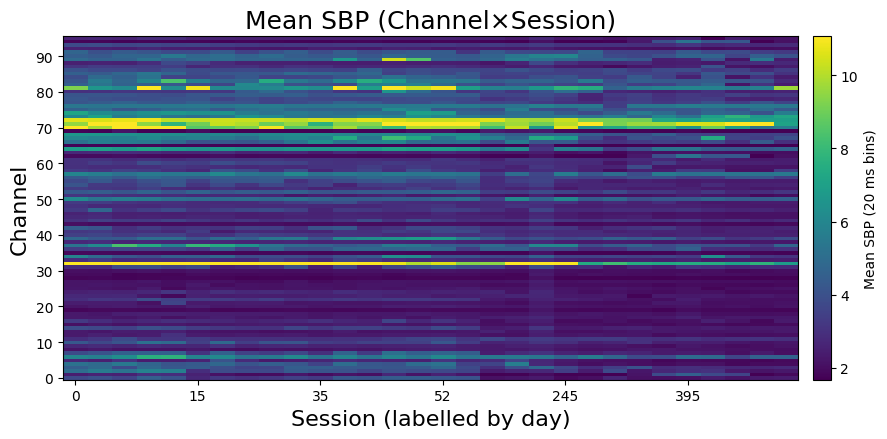

In [9]:
# ----- Plot 1: Channel × session heatmap (mean SBP) -----

import importlib
import neurosignal.gold.drift_plots as dp
importlib.reload(dp)

from neurosignal.gold import plot_session_channel_heatmap
import matplotlib.pyplot as plt



n_ch = sessions_sbp[0].shape[1]
mean_per_session = [np.nanmean(sbp, axis=0) for sbp in sessions_sbp]

fig1 = plot_session_channel_heatmap(mean_per_session, session_dates, days_on_x=True)
save_figure(fig1, "signal_decoder_demo", "sbp_channel_by_day_heatmap", role="candidate_supporting")
plt.show()

### Plot 1b: The spatial fingerprint is real

Averaged across sessions, channels keep a recognizable relative profile (tight SEM), so this is not random noise chaos.

But that makes the problem harder: the profile exists, yet global and channel-specific amplitude scales still drift over time.

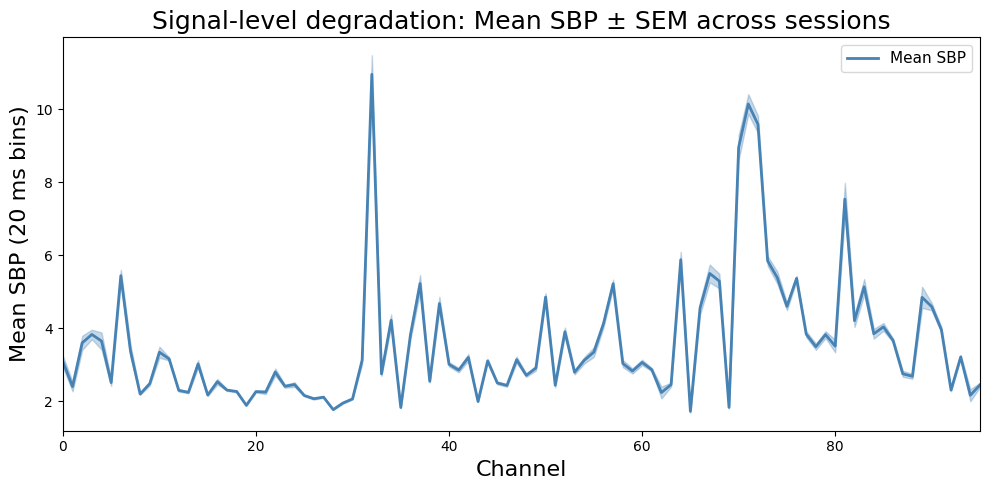

In [10]:
from neurosignal.gold.drift_plots import plot_signal_degradation_mean_sem

fig1c = plot_signal_degradation_mean_sem(mean_per_session, session_dates, n_ch)
save_figure(fig1c, "signal_decoder_demo", "signal_degradation_mean_sem", role="candidate_supporting")
plt.show()

### Plot 1c/1d: Each channel drifts differently

Day 0 vs late-day scatter and the small-multiples view show asymmetric drift: many channels decay, some spike upward, and high-amplitude channels can collapse.

So this is not a one-parameter gain correction problem. The representation itself shifts.

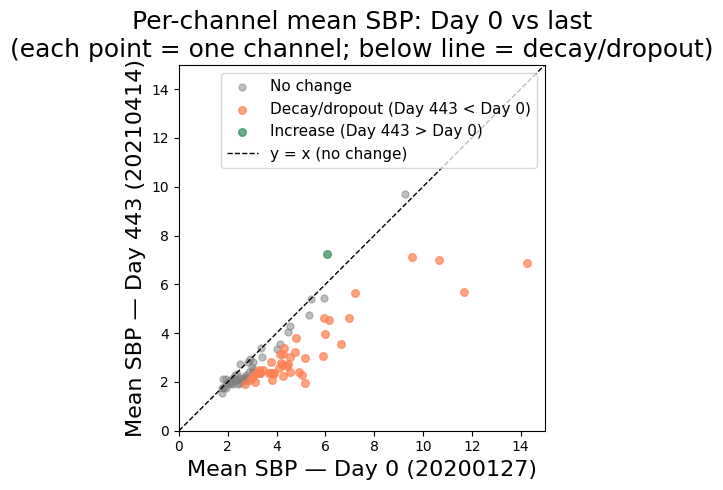

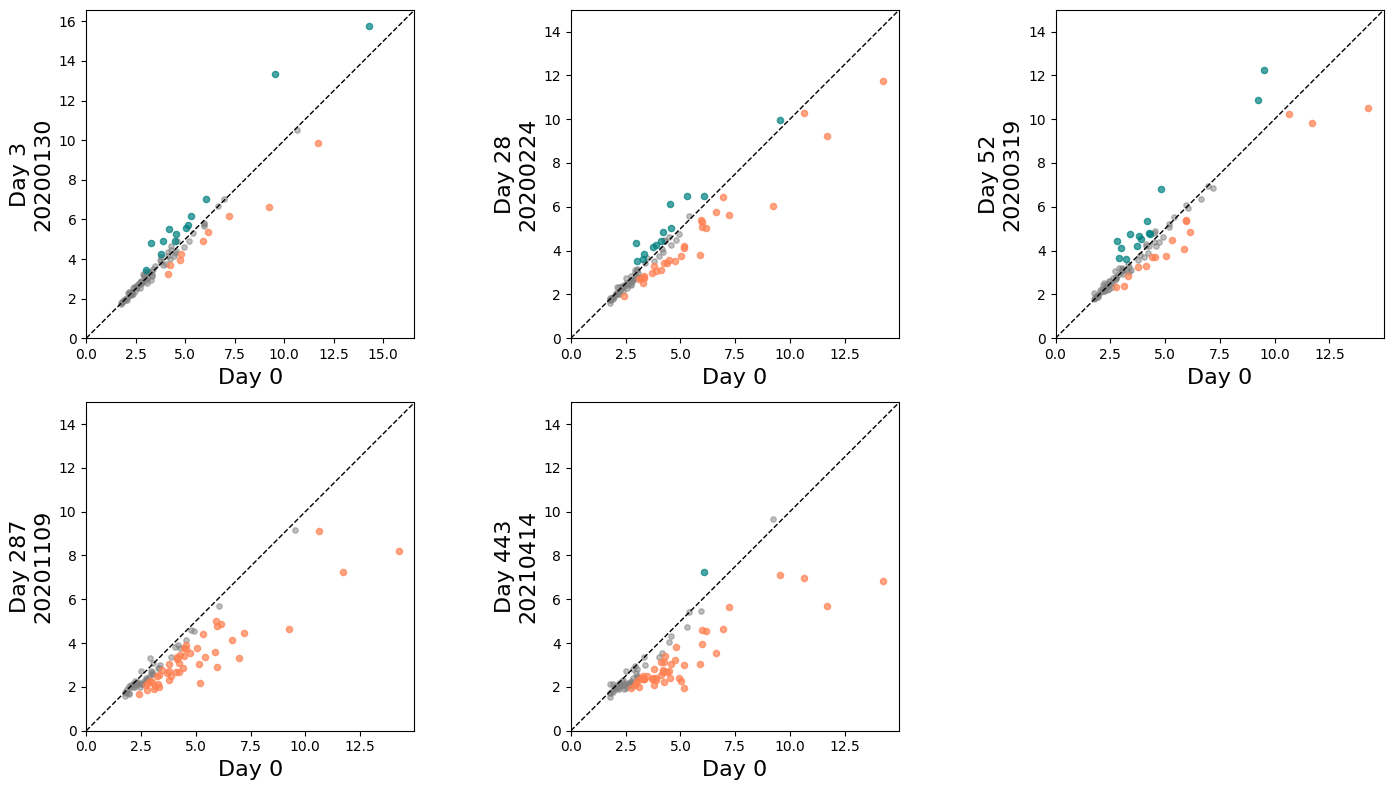

In [11]:
from neurosignal.gold import plot_day0_vs_last_scatter, plot_per_channel_drift_small_multiples
import matplotlib.pyplot as plt

fig1b = plot_day0_vs_last_scatter(
    mean_per_session[0], mean_per_session[-1], session_dates, N
)
save_figure(fig1b, "signal_decoder_demo", "day0_vs_last_scatter", role="candidate_supporting")
plt.show()

# ----- Fig 1b paper: small multiples (Day 0 vs several later sessions), save to output -----
fig_small = plot_per_channel_drift_small_multiples(mean_per_session, session_dates)
save_figure(fig_small, "signal_decoder_demo", "per_channel_drift_small_multiples", role="candidate_supporting")
plt.show()

## The part that actually matters: decoder failure

I train on Day 0 and transfer that model forward without recalibration.

Negative R² here means more than "bad"; it means the model is doing worse than a no-skill baseline for that test day. So when bars fall below zero across time gaps, transfer is not just degraded, it's actively unreliable.

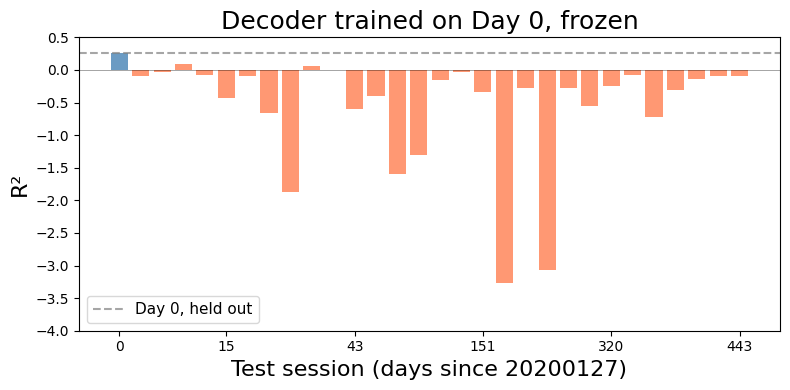

Day 0 R² (held out): 0.2613 (in-sample, superseded: 0.2993) | day 443 (20210414) R²: -0.0888 | Drop: 0.3501
Later sessions with R² < 0: 27 of 29 | lowest: -3.2742 on day 163 (20200708) | median of later sessions: -0.2706


In [12]:
# ----- Plot 2: Decoder degradation on Day K -----
from neurosignal.gold.drift import compute_day_offsets
from neurosignal.gold import (
    compute_decoder_r2_per_day,
    plot_decoder_degradation,
    degradation_table,
)
import matplotlib.pyplot as plt
import numpy as np

R2_PLOT_FLOOR = globals().get("R2_PLOT_FLOOR", -20.0)

# Use QC-derived bad dates (set in the QC cell)
BAD_SESSION_DATES = globals().get("QC_BAD_SESSION_DATES", set())

# Filter sessions once, so bad days never enter the decoder
keep_idx = [i for i, d in enumerate(session_dates) if d not in BAD_SESSION_DATES]
drop_idx = [i for i, d in enumerate(session_dates) if d in BAD_SESSION_DATES]

if drop_idx:
    print(f"Dropping {len(drop_idx)} session(s) from decoder analysis:")
    for i in drop_idx:
        print(f"  session {i} | {session_dates[i]}")

sessions_sbp_f = [sessions_sbp[i] for i in keep_idx]
sessions_vel_f = [sessions_vel[i] for i in keep_idx]
session_dates_f = [session_dates[i] for i in keep_idx]
N = len(session_dates_f)

# Compute degradation on the filtered set
r2_day_k, model = compute_decoder_r2_per_day(sessions_sbp_f, sessions_vel_f)
fig = plot_decoder_degradation(
    r2_day_k,
    session_dates_f,
    clip_floor=R2_PLOT_FLOOR,
    ylim=(-4.0, 0.5),
)
save_figure(fig, "signal_decoder_demo", "decoder_degradation_day_k_no_outliers", role="candidate_supporting")
plt.show()

PRINT_DEGRADATION_TABLE = False
df_degradation = degradation_table(r2_day_k, session_dates_f)
day_of = compute_day_offsets(session_dates_f).astype(int)
# Day 0 is scored on held-out blocks (5 folds, EXP-001); the old in-sample value is shown for reference only.
r2_day0_in_sample = compute_decoder_r2_per_day(sessions_sbp_f, sessions_vel_f, heldout_day0=False)[0][0]
later = r2_day_k[1:]
k_min = 1 + int(np.argmin(later))
if PRINT_DEGRADATION_TABLE:
    print(df_degradation.to_string(index=False))
print(
    f"Day 0 R² (held out): {r2_day_k[0]:.4f} (in-sample, superseded: {r2_day0_in_sample:.4f}) | "
    f"day {day_of[-1]} ({session_dates_f[-1]}) R²: {r2_day_k[-1]:.4f} | "
    f"Drop: {r2_day_k[0] - r2_day_k[-1]:.4f}"
)
print(
    f"Later sessions with R² < 0: {int((later < 0).sum())} of {later.size} | "
    f"lowest: {later.min():.4f} on day {day_of[k_min]} ({session_dates_f[k_min]}) | "
    f"median of later sessions: {np.median(later):.4f}"
)

below_floor = np.where(r2_day_k < R2_PLOT_FLOOR)[0]
if below_floor.size:
    print(f"\n[QC] Sessions below plot floor ({R2_PLOT_FLOOR:.0f}):")
    for i in below_floor:
        print(f"day {day_of[i]} | {session_dates_f[i]} | raw R² = {r2_day_k[i]:.4f}")

if np.abs(r2_day_k).max() < 0.05:
    print(
        "\n[Note] R² ≈ 0: decoder (pop SBP → velocity) has almost no predictive power. "
        "Check time alignment and that index_velocity is the right target."
    )

1–7 d: n = 1, median R² -0.0961, min -0.0961
8–30 d: n = 7, median R² -0.0890, min -1.8688
>30 d: n = 21, median R² -0.2769, min -3.2742


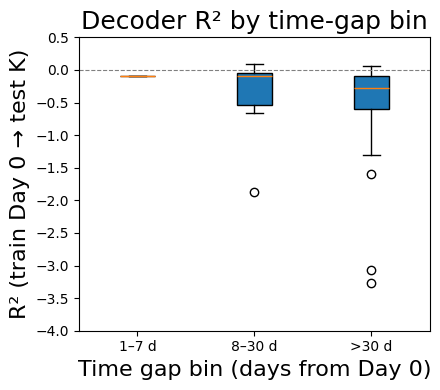

In [13]:
# ----- Plot 2B: Decoder R² by time-gap bin (boxplot) -----
from neurosignal.gold import plot_decoder_r2_boxplot_by_gap

fig_box = plot_decoder_r2_boxplot_by_gap(
    r2_day_k,
    session_dates_f,
    ylim=(-4.0, 0.5),
)
gaps = compute_day_offsets(session_dates_f)
for lo, hi, label in [(1, 7, "1–7 d"), (8, 30, "8–30 d"), (31, np.inf, ">30 d")]:
    vals = r2_day_k[(gaps >= lo) & (gaps <= hi)]
    print(f"{label}: n = {vals.size}, median R² {np.median(vals):.4f}, min {vals.min():.4f}")
save_figure(fig_box, "signal_decoder_demo", "decoder_r2_boxplot_by_gap_bin", role="candidate_supporting")
plt.show()

## What the data is telling

- Raw chronic SBP is not stationary across sessions.
- Per-channel drift is asymmetric, not a simple global shift.
- Cross-day transfer from a fixed Day-0 decoder is mostly negative.

The signal still contains movement information, but the representation moves enough over time that static mapping breaks.

## What's next

Part 2 introduces **Gold r_norm** as a lightweight normalization step to stabilize cross-day decoding without requiring explicit cross-day alignment labels.

## References

- Magland, J. F., Ly, R., Rubel, O., & Dichter, B. K. (2025). Facilitating analysis of open neurophysiology data on the DANDI Archive using large language model tools. *Scientific Data*, 12, 285. https://doi.org/10.1038/s41597-025-06285-x
- Rubel, O., Tritt, A., Ly, R., Dichter, B. K., Ghosh, S., Niu, L., Baker, P., Soltesz, I., Ng, L., Svoboda, K., Frank, L., & Bouchard, K. E. (2022). The Neurodata Without Borders ecosystem for neurophysiological data science. *eLife*, 11, e78362. https://doi.org/10.7554/eLife.78362